# Fin-JEPA on In-House Fraud Detection Dataset

End-to-end training, validation-based checkpoint selection (`A_repo` vs. `E_ema`), and multi-seed test evaluation of **Fin-JEPA** (`cedricwyh/fin-jepa`) on `43,716` transactions (`22,991` train / `20,725` test, `127` frauds).

## Step 1 — Environment, Repository & Data Load

Sets random seeds, clones `cedricwyh/fin-jepa`, loads `sequences.csv`, `label_timeline.csv`, and `_ground_truth.csv`, and audits chronological train/test coverage.

In [1]:
import contextlib, copy, glob, io, os, random, subprocess, sys, time, warnings, zipfile
warnings.filterwarnings("ignore")

ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.path.abspath("./work")     # outputs (csv, npz, checkpoints) are written here
os.makedirs(WORK, exist_ok=True)

# ---- configuration ----
SEED = 42
FINJEPA_REPO = "https://github.com/cedricwyh/fin-jepa"
FINJEPA_COMMIT = "58506d6e31ecb2c65f9c69ea1f1bc146ef08f8b9"   # pinned for reproducibility; None = latest

# ---- 1. dependency used by the Fin-JEPA model file ----
try:
    import einops  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "einops"], check=False)

# ---- 2. clone Fin-JEPA at run time (needs internet: Kaggle -> Notebook settings -> Internet) ----
# The repository has no licence file, so its code is cloned here and never copied into this project.
def _git(*args, cwd=None):
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("git failed (is internet enabled?): " + " ".join(args) + "\n" + r.stderr[-400:])

FIN_DIR = os.path.join(WORK, "repos", "fin-jepa")
if not (os.path.isdir(FIN_DIR) and os.listdir(FIN_DIR)):
    os.makedirs(os.path.dirname(FIN_DIR), exist_ok=True)
    _git("clone", "--depth", "1", FINJEPA_REPO, FIN_DIR)
    if FINJEPA_COMMIT:
        _git("fetch", "--depth", "1", "origin", FINJEPA_COMMIT, cwd=FIN_DIR)
        _git("checkout", "-q", "FETCH_HEAD", cwd=FIN_DIR)

# model.py declares `class Fin-JEPA(...)`: a hyphen is not valid in a Python identifier, so the file cannot be
# imported as shipped. We write a patched COPY (only the identifier changes) and leave the clone untouched.
PATCH_DIR = os.path.join(WORK, "finjepa_patched"); os.makedirs(PATCH_DIR, exist_ok=True)
_src = open(os.path.join(FIN_DIR, "model.py"), encoding="utf-8").read()
_patched = _src.replace("class Fin-JEPA(", "class FinJEPA(").replace("= Fin-JEPA(", "= FinJEPA(")
compile(_patched, "finjepa_model.py", "exec")            # fails loudly if the upstream file changes in an unexpected way
open(os.path.join(PATCH_DIR, "finjepa_model.py"), "w", encoding="utf-8").write(_patched)
sys.path.insert(0, PATCH_DIR)

# ---- 3. imports ----
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from types import SimpleNamespace as NS
from finjepa_model import FinJEPA, SIGReg                 # PriceEncoder / TransformerPredictor / SIGReg are used unchanged

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "  <-- turn on a GPU for training"))
print(f"torch {torch.__version__} | Fin-JEPA repo: {FIN_DIR}")

# ---- 4. check that the patched Fin-JEPA model runs: encoder -> causal predictor -> SIGReg on a dummy batch ----
_m = FinJEPA(n_features=8, embed_dim=64, predictor_layers=4, sigreg_proj=128).to(DEVICE)
_x = torch.randn(4, 10, 8, device=DEVICE)                  # (batch, time steps, features)
_z = _m.encode_batch(_x); _zp = _m.predictor(_z); _sig = _m.sigreg(_z.reshape(1, -1, 64))
assert _z.shape == _zp.shape == (4, 10, 64) and torch.isfinite(_sig)
print(f"Fin-JEPA OK: {sum(p.numel() for p in _m.parameters()):,} params | encoder out {tuple(_z.shape)} -> predictor out {tuple(_zp.shape)} | SIGReg {float(_sig):.2f}")
del _m, _x, _z, _zp, _sig

# ---- 5. locate + load the three dataset files ----
def find_data_dir():
    if os.environ.get("FRAUD_DATA_DIR"): return os.environ["FRAUD_DATA_DIR"]
    hits = glob.glob("/kaggle/input/**/sequences.*", recursive=True)
    if hits: return os.path.dirname(hits[0])
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        out = os.path.join(WORK, "data"); os.makedirs(out, exist_ok=True)
        zipfile.ZipFile(z).extractall(out)
        hits = glob.glob(out + "/**/sequences.*", recursive=True)
        if hits: return os.path.dirname(hits[0])
    raise FileNotFoundError("sequences.csv not found - add the dataset to this notebook (Add data)")

def read(d, stem):
    for ext in (".csv", ".parquet"):
        p = os.path.join(d, stem + ext)
        if os.path.exists(p): return pd.read_csv(p) if ext == ".csv" else pd.read_parquet(p)
    raise FileNotFoundError(f"{stem}.csv/.parquet not found in {d}")

DD = find_data_dir()
seq, lab, gt = read(DD, "sequences"), read(DD, "label_timeline"), read(DD, "_ground_truth")
print(f"\ndata dir: {DD}")
print(f"sequences {seq.shape} | label_timeline {lab.shape} | ground_truth {gt.shape}")

# ---- 6. integrity checks ----
assert seq["id"].is_unique and lab["charge_id"].is_unique and gt["charge_id"].is_unique, "duplicate ids"
assert set(seq["id"]) == set(lab["charge_id"]) == set(gt["charge_id"]), "id sets differ between files"
assert (lab.set_index("charge_id")["split"].reindex(seq["id"]).values == seq["split"].values).all(), "split mismatch"
print("integrity checks passed (ids unique and aligned, split identical across files)")

# ---- 7. merge features + delayed labels; ground truth stays SEPARATE (evaluation only) ----
df = seq.merge(lab.drop(columns=["t_event", "split"]), left_on="id", right_on="charge_id",
               how="left", validate="1:1").drop(columns=["charge_id"])
df["t"] = pd.to_datetime(df["created"])
df = df.sort_values(["customer_id", "t", "id"]).reset_index(drop=True)      # customers contiguous, time-ordered inside each
df["pos"] = df.groupby("customer_id").cumcount()                           # 0 = the customer's first charge
_g = gt.set_index("charge_id").reindex(df["id"])
Y_TRUE = _g["is_fraud"].astype(int).values
TYP = _g["typology"].astype(str).values
IS_TRAIN = (df["split"] == "train").values
IS_TEST = (df["split"] == "test").values
T_CUT = df.loc[IS_TEST, "t"].min()
N = len(df)

# ---- 8. audit (ground truth shown here for understanding only; no model sees it) ----
print(f"\nrows={N:,} | train={IS_TRAIN.sum():,} | test={IS_TEST.sum():,} | time range {df['t'].min().date()} -> {df['t'].max().date()} | split at {T_CUT}")
aud = pd.DataFrame({"split": df["split"], "typology": TYP, "fraud": Y_TRUE})
print("\nfraud by split x typology:")
print(aud.groupby(["split", "typology"]).fraud.agg(rows="size", fraud="sum").assign(rate=lambda x: (x.fraud / x.rows).round(4)).to_string())
print(f"\noverall fraud rate: train {Y_TRUE[IS_TRAIN].mean():.3%} | test {Y_TRUE[IS_TEST].mean():.3%}")

nul = df.isna().mean(); nul = nul[nul > 0]
print("\ncolumns with missing values (fraction):")
print(nul.round(4).to_string())

# ---- 9. sequence audit: Fin-JEPA reads each charge together with the customer's EARLIER charges ----
cc = df.groupby("customer_id").size()
print(f"\ncustomers: {len(cc):,} | charges per customer: median {cc.median():.0f}, 90th pct {cc.quantile(.9):.0f}, max {cc.max()}")
print("share of charges that have at least k earlier charges of the same customer (any period, past only):")
p = df["pos"].values
print(pd.DataFrame({f">= {k}": [np.mean(p[m] >= k) for m in (IS_TRAIN, IS_TEST)] for k in (1, 2, 4, 8, 16, 31)}, index=["train", "test"]).round(3).to_string())
has_train = pd.Series(IS_TRAIN).groupby(df["customer_id"].values).transform("any").values
print(f"test charges whose customer already has train-period charges (usable as context): {(IS_TEST & has_train).sum():,} of {IS_TEST.sum():,} ({(IS_TEST & has_train).sum() / IS_TEST.sum():.1%})")
print(f"test charges with at least one earlier charge of any period: {(IS_TEST & (p > 0)).sum():,} ({(IS_TEST & (p > 0)).sum() / IS_TEST.sum():.1%}) | first-ever charges (no context): {(IS_TEST & (p == 0)).sum():,}")

device: cuda (Tesla T4)
torch 2.11.0+cu130 | Fin-JEPA repo: /kaggle/working/repos/fin-jepa
Fin-JEPA OK: 267,136 params | encoder out (4, 10, 64) -> predictor out (4, 10, 64) | SIGReg 16.52

data dir: /kaggle/input/datasets/abhradwiplala/in-house-dataset
sequences (43716, 51) | label_timeline (43716, 15) | ground_truth (43716, 3)
integrity checks passed (ids unique and aligned, split identical across files)

rows=43,716 | train=22,991 | test=20,725 | time range 2026-01-05 -> 2026-07-03 | split at 2026-04-23 00:18:05.424984229

fraud by split x typology:
                 rows  fraud    rate
split typology                      
test  ato         151     24  0.1589
      emerge      415     96  0.2313
      normal    20159      7  0.0003
train ato          78     17  0.2179
      normal    22455     12  0.0005
      ring        458    140  0.3057

overall fraud rate: train 0.735% | test 0.613%

columns with missing values (fraction):
bank_account_id       1.0000
source_id             1.000

## Step 2 — Feature Engineering & Fin-JEPA Input Matrix

Builds numeric, categorical, and behavioral features with train-only scaling and zero clipping of high-cardinality codes.

In [2]:
# ---- configuration for this step ----
VAL_START = pd.Timestamp("2026-03-09")   # chronological validation window = [VAL_START, split date); same as the T-JEPA notebook
TAIL_START = pd.Timestamp("2026-04-07")  # the 7-23 Apr window, reported separately
CLIP = 5.0                               # clip for CONTINUOUS features only (None = no clipping); binary flags / one-hot are never clipped
USE_EXTRA = False                        # True = add the behaviour features below (kept OFF for the baseline; used in the ablation)

SSL_TRAIN = IS_TRAIN & (df["t"] < VAL_START).values      # rows used to fit scalers (and later to pretrain) during model selection
VAL_WIN = IS_TRAIN & (df["t"] >= VAL_START).values

# ---- 1. past-only card-reuse features (no future leakage) ----
def causal_card_features(d):
    """per charge: #EARLIER charges on the same card fingerprint, #distinct OTHER customers who used it earlier"""
    order = np.argsort(d["t"].values, kind="stable")
    fp, cu = d["card_fingerprint"].values, d["customer_id"].values
    cnt, who = {}, {}
    pn = np.zeros(len(d), np.float32); po = np.zeros(len(d), np.float32)
    for i in order:
        f = fp[i]; pn[i] = cnt.get(f, 0)
        s = who.setdefault(f, set()); po[i] = len(s) - (1 if cu[i] in s else 0)
        cnt[f] = cnt.get(f, 0) + 1; s.add(cu[i])
    return pn, po

# ---- 2. the 29 base features (identical to the T-JEPA notebook, so both models see the same information) ----
def engineer(d):
    X = pd.DataFrame(index=d.index); la = d["log_amount"]
    # customers with little/no history: explicit flags BEFORE filling; rows are never dropped
    X["no_prev"]  = d["secs_since_prev"].isna().astype(np.float32)        # customer's first charge
    X["lt2_hist"] = d["log_amount_cumstd"].isna().astype(np.float32)      # <2 earlier charges: std undefined
    X["log_amount"] = la
    X["log_amount_prev"]    = d["log_amount_prev"].fillna(la)             # no history -> "same as now"
    X["log_amount_cummean"] = d["log_amount_cummean"].fillna(la)
    X["log_amount_cumstd"]  = d["log_amount_cumstd"].fillna(0.0)
    X["log_amount_z"]       = d["log_amount_z"].fillna(0.0).clip(-10, 10)
    X["amt_vs_prev"]        = la - X["log_amount_prev"]
    X["secs_since_prev"]    = np.log1p(d["secs_since_prev"])              # NaN -> train median in build_matrix
    X["secs_since_first"]   = np.log1p(d["secs_since_first"])
    X["cus_age_days"]       = np.log1p(d["cus_age_days"])
    X["seq_pos"]            = np.log1p(d["seq_pos"])
    for c in ("velocity_1h", "velocity_24h", "velocity_7d"): X[c] = np.log1p(d[c])
    for c in ("geo_mismatch_cus", "geo_mismatch_card", "cvc_failed"): X[c] = d[c].astype(np.float32)
    X["captured"] = d["captured"].astype(np.float32)
    X["hour_sin"] = np.sin(2*np.pi*d["hour"]/24); X["hour_cos"] = np.cos(2*np.pi*d["hour"]/24)
    X["dow_sin"]  = np.sin(2*np.pi*d["dow"]/7);   X["dow_cos"]  = np.cos(2*np.pi*d["dow"]/7)
    X["is_night"] = (d["hour"] < 6).astype(np.float32)
    X["cross_border"] = (d["billing_detail_address_country"] != d["acct_country"]).astype(np.float32)
    X["card_vs_cus"]  = (d["card_country"] != d["cus_country"]).astype(np.float32)
    X["acct_vs_cus"]  = (d["acct_country"] != d["cus_country"]).astype(np.float32)
    pn, po = causal_card_features(d)
    X["fp_prior_n"] = np.log1p(pn); X["fp_prior_other_cust"] = np.log1p(po)
    return X

# ---- 3. optional behaviour features (all past-only; switched on with USE_EXTRA for the ablation) ----
def engineer_extra(d):
    X = pd.DataFrame(index=d.index)
    pos, sf, sp = d["seq_pos"], d["secs_since_first"], d["secs_since_prev"]
    # change in transaction frequency: current gap vs the mean of the customer's PREVIOUS gaps (needs >= 2 earlier charges)
    prev_mean_gap = (sf - sp) / (pos - 1).where(pos >= 2)
    X["gap_ratio"] = (np.log1p(sp) - np.log1p(prev_mean_gap)).where(pos >= 2, 0.0)
    # unusual amount: current amount vs the largest of the customer's EARLIER amounts
    prev_max = d.groupby("customer_id")["log_amount"].cummax().groupby(d["customer_id"]).shift(1)
    X["amt_vs_max_prev"] = (d["log_amount"] - prev_max).fillna(0.0)
    # burstiness: charges in the last hour relative to the last 24 hours
    X["burst_ratio"] = np.log1p(d["velocity_1h"]) - np.log1p(d["velocity_24h"])
    return X

CAT_COLS = ["billing_detail_address_country", "billing_detail_address_city", "card_brand", "card_funding",
            "card_country", "card_cvc_check", "card_issuer", "cus_country", "cus_city", "mcc",
            "acct_country", "acct_structure"]
# Deliberately NOT used: ids, raw card_fingerprint/iin, timestamps, constant `currency`, all-null columns,
# every label_timeline column (y_*, t_*, lag_*), and the raw-scale amount stats (amount_z reaches +-8000).
XBASE, XEXTRA = engineer(df), engineer_extra(df)
NUM_COLS, EXTRA_COLS = list(XBASE.columns), list(XEXTRA.columns)
XALL = pd.concat([XBASE, XEXTRA], axis=1)

# ---- 4. leakage test: features of early charges must not change when all LATER data is removed ----
cut = df["t"].quantile(0.5); early = df[df["t"] <= cut]
XT = pd.concat([engineer(early), engineer_extra(early)], axis=1)
diff = (XT - XALL.loc[XT.index, XT.columns]).abs().max().max()
print(f"causality check: recomputing every engineered feature on data truncated at {cut.date()} changes the {len(early):,} earlier rows by max |diff| = {diff:.1e}")
assert diff < 1e-6, "a feature uses future information"

# ---- 5. Fin-JEPA input matrix: continuous standardised (+ optional clip), binary raw 0/1, categoricals ONE-HOT ----
def build_matrix(fit_mask, clip=CLIP, extra=USE_EXTRA):
    """scalers / vocabularies are fitted on the rows of fit_mask only.
       categoricals are one-hot encoded (index 0 = unseen category), so there are no ordinal codes to clip or mis-scale."""
    cols = NUM_COLS + (EXTRA_COLS if extra else [])
    Xn = XALL[cols].copy()
    bin_cols = [c for c in cols if set(np.unique(Xn.loc[fit_mask, c].dropna())) <= {0.0, 1.0}]
    cont = [c for c in cols if c not in bin_cols]
    med = Xn.loc[fit_mask, cont].median(); Xn[cont] = Xn[cont].fillna(med)
    mu, sd = Xn.loc[fit_mask, cont].mean(), Xn.loc[fit_mask, cont].std().replace(0, 1.0).fillna(1.0)
    Z = (Xn[cont] - mu) / sd; raw = Z.copy()
    Xn[cont] = Z.clip(-clip, clip) if clip is not None else Z
    vocab = {c: {v: i + 1 for i, v in enumerate(sorted(df.loc[fit_mask, c].astype(str).unique()))} for c in CAT_COLS}
    card = [len(vocab[c]) + 1 for c in CAT_COLS]
    codes = np.stack([df[c].astype(str).map(vocab[c]).fillna(0).astype(np.int64).values for c in CAT_COLS], 1)
    onehot = [np.eye(k, dtype=np.float32)[codes[:, j]] for j, k in enumerate(card)]
    X = np.hstack([Xn[cols].values.astype(np.float32)] + onehot).astype(np.float32)
    return dict(X=X, cols=cols, bin=bin_cols, cont=cont, card=card, codes=codes, raw=raw)

M = build_matrix(SSL_TRAIN)
X_FIN, XC, CARD, RAW = M["X"], M["codes"], M["card"], M["raw"]
N_NUM = len(M["cols"]); F_IN = X_FIN.shape[1]
assert np.isfinite(X_FIN).all(), "NaN/inf left in X_FIN"

# ---- 6. report ----
print(f"\nFin-JEPA input: {N_NUM} numeric ({len(M['bin'])} binary flags kept raw 0/1, {len(M['cont'])} continuous standardised, clip={CLIP}) "
      f"+ {len(CAT_COLS)} categorical one-hot ({sum(CARD)} columns) = {F_IN} features per charge | X_FIN {X_FIN.shape}")
print("categorical cardinalities (incl. unknown):", dict(zip(CAT_COLS, CARD)))
print("test rows with an unseen category:", {c: round(float((XC[IS_TEST][:, j] == 0).mean()), 4) for j, c in enumerate(CAT_COLS) if (XC[IS_TEST][:, j] == 0).any()} or "none")
print(f"history-less rows kept, not dropped: first charge {df['pos'].eq(0).mean():.1%} -> no_prev=1 | fewer than 2 earlier charges {df['pos'].le(1).mean():.1%} -> lt2_hist=1")

ac = RAW.abs() > (CLIP if CLIP is not None else 1e9)
cl = pd.DataFrame({"ssl_train": ac[SSL_TRAIN].mean(), "val": ac[VAL_WIN].mean(), "test": ac[IS_TEST].mean()})
print(f"\nshare of values clipped at +-{CLIP} (continuous features; only those > 0.1% in any period shown), percent:")
print((cl[(cl > 0.001).any(axis=1)] * 100).round(2).to_string() if (cl > 0.001).any().any() else "none above 0.1%")

print(f"\noptional behaviour features (OFF unless USE_EXTRA=True; USE_EXTRA={USE_EXTRA}):")
print(XEXTRA.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())
print(f"  neutral-filled (no usable history): gap_ratio {(df['seq_pos'] < 2).mean():.1%} of rows, amt_vs_max_prev {(df['seq_pos'] < 1).mean():.1%}")

mm = pd.DataFrame({"train": X_FIN[IS_TRAIN, :N_NUM].mean(0), "test": X_FIN[IS_TEST, :N_NUM].mean(0)}, index=M["cols"])
print("\nlargest train->test mean shifts among the numeric inputs (label-free drift check):")
print(mm.assign(shift=(mm.test - mm.train).abs()).sort_values("shift", ascending=False).head(5).round(3).to_string())

causality check: recomputing every engineered feature on data truncated at 2026-04-17 changes the 21,858 earlier rows by max |diff| = 0.0e+00

Fin-JEPA input: 29 numeric (10 binary flags kept raw 0/1, 19 continuous standardised, clip=5.0) + 12 categorical one-hot (163 columns) = 192 features per charge | X_FIN (43716, 192)
categorical cardinalities (incl. unknown): {'billing_detail_address_country': 9, 'billing_detail_address_city': 19, 'card_brand': 6, 'card_funding': 4, 'card_country': 9, 'card_cvc_check': 4, 'card_issuer': 60, 'cus_country': 9, 'cus_city': 19, 'mcc': 11, 'acct_country': 9, 'acct_structure': 4}
test rows with an unseen category: none
history-less rows kept, not dropped: first charge 9.1% -> no_prev=1 | fewer than 2 earlier charges 18.1% -> lt2_hist=1

share of values clipped at +-5.0 (continuous features; only those > 0.1% in any period shown), percent:
                     ssl_train   val  test
log_amount_cummean        0.00  0.00  0.64
log_amount_z              1.4

## Step 3 — Label Timeline, Chronological Splits & Class Imbalance

Defines the validation window (`2026-03-09` to `2026-04-22`) and inspects positive/negative class counts across splits.

In [3]:
# The logic is identical to the T-JEPA notebook, so both models use exactly the same rows and labels.

LABEL_CHANNELS = ("efw", "dispute")   # fraud-specific channels (precise). review/refund are mostly NOT fraud.
MATURITY_DAYS = 14.0                  # rows younger than this at the split date have unreliable "no label yet"
VAL_FRAC = 0.25                       # share of the supervised pool held out for early stopping / selection
MIN_VAL_POS = 25                      # fewer positives than this in a time-based val block -> grouped split
POS_WEIGHT_CAP = 30.0

# ---- 1. which labels would we REALLY know on a given date? ----
# a label channel arrives lag_<channel>_days after the charge; it is usable only if it had arrived by that date
def known_as_of(T, chs=LABEL_CHANNELS):
    k = np.zeros(N, bool); av = (T - df["t"]).dt.total_seconds().values / 86400.0
    for ch in chs:
        y = (df[f"y_{ch}"].fillna(0).values == 1); lag = df[f"lag_{ch}_days"].values.astype(float)   # NaN lag = never arrives
        k |= y & np.isfinite(lag) & (lag <= av)
    return k

Y_OBS = known_as_of(T_CUT).astype(int)                                   # labels known on the split date (final head)

# ---- 2. supervised pool for the FINAL head: train rows old enough that "no label" really means "not flagged" ----
MATURE = (df["t"] <= T_CUT - pd.Timedelta(days=MATURITY_DAYS)).values
POOL = IS_TRAIN & MATURE

# ---- 3. grouped validation split inside the pool (used to early-stop the MLP head); test is never touched ----
def split_time():
    pi = np.flatnonzero(POOL); pi = pi[np.argsort(df["t"].values[pi], kind="stable")]
    v = np.zeros(N, bool); v[pi[-int(len(pi) * VAL_FRAC):]] = True; return v

def split_group():
    """customer-grouped + stratified by 'customer has an observed positive': no customer is in both FIT and VAL"""
    rng = np.random.RandomState(SEED); cust = df["customer_id"].values
    hp = pd.Series(Y_OBS[POOL]).groupby(cust[POOL]).max()
    pos_c, neg_c = hp[hp == 1].index.values, hp[hp == 0].index.values
    vc = np.concatenate([rng.choice(pos_c, max(1, int(len(pos_c) * VAL_FRAC)), replace=False),
                         rng.choice(neg_c, int(len(neg_c) * VAL_FRAC), replace=False)])
    return POOL & np.isin(cust, vc)

VAL = split_time() & POOL
n_time_pos = int(Y_OBS[VAL].sum())
if n_time_pos < MIN_VAL_POS:
    print(f"NOTE: time-based validation block has only {n_time_pos} observed positives (<{MIN_VAL_POS}) "
          "-> using a customer-grouped stratified split instead.")
    VAL = split_group()
FIT = POOL & ~VAL
assert not (FIT & VAL).any() and not (VAL & IS_TEST).any() and not (FIT & IS_TEST).any()

n_pos, n_neg = int(Y_OBS[FIT].sum()), int((Y_OBS[FIT] == 0).sum())
POS_WEIGHT = float(min(n_neg / max(n_pos, 1), POS_WEIGHT_CAP))

# ---- 4. chronological splits for model selection (pretraining and scalers see only rows before VAL_START) ----
VAL_TAIL = IS_TRAIN & (df["t"] >= TAIL_START).values                     # the 7-23 Apr window (subset of VAL_WIN)
HEAD_FIT_V = SSL_TRAIN & (df["t"] <= VAL_START - pd.Timedelta(days=MATURITY_DAYS)).values   # mature as of VAL_START
Y_OBS_V = (known_as_of(VAL_START) & HEAD_FIT_V).astype(int)              # labels that existed on VAL_START only
assert not (SSL_TRAIN & VAL_WIN).any() and not (VAL_WIN & IS_TEST).any()
assert df.loc[SSL_TRAIN, "t"].max() < df.loc[VAL_WIN, "t"].min() <= df.loc[IS_TEST, "t"].min()

# ---- 5. report ----
print(f"label channels used: {LABEL_CHANNELS} | maturity {MATURITY_DAYS:.0f} days | split date {T_CUT}\n")
tab = pd.DataFrame({
    "rows":         [FIT.sum(), VAL.sum(), (IS_TRAIN & ~POOL).sum(), IS_TEST.sum()],
    "observed_pos": [Y_OBS[FIT].sum(), Y_OBS[VAL].sum(), Y_OBS[IS_TRAIN & ~POOL].sum(), Y_OBS[IS_TEST].sum()],
}, index=["FIT (train head)", "VAL (early stop/select)", "train, too recent (no supervision)", "TEST (partial labels shown for info)"])
tab["pos_rate"] = (tab.observed_pos / tab.rows).round(4)
print(tab.to_string())

print("\nhow complete are the observed labels? (train pool only, vs hidden truth - for understanding)")
for nm, m in (("FIT", FIT), ("VAL", VAL)):
    tp = ((Y_OBS == 1) & (Y_TRUE == 1) & m).sum()
    print(f"  {nm}: true frauds={int((Y_TRUE[m]==1).sum())} | labelled={int(Y_OBS[m].sum())} | "
          f"label precision={tp / max(Y_OBS[m].sum(), 1):.2f} | label recall={tp / max((Y_TRUE[m] == 1).sum(), 1):.2f}")
print("  fraud types among OBSERVED positives in FIT+VAL:", pd.Series(TYP[(FIT | VAL) & (Y_OBS == 1)]).value_counts().to_dict())
print(f"\nimbalance in FIT: {n_pos} positives vs {n_neg:,} negatives (1:{n_neg / max(n_pos, 1):.0f}) -> class weight (capped at {POS_WEIGHT_CAP:.0f}) = {POS_WEIGHT:.1f}")

def _s(m, y, nm): return dict(split=nm, rows=int(m.sum()), first=str(df.loc[m, "t"].min().date()), last=str(df.loc[m, "t"].max().date()),
                              labelled_pos=int(y[m].sum()) if y is not None else "-", true_frauds=int(Y_TRUE[m].sum()))
print("\nchronological splits for model selection (no overlap):")
print(pd.DataFrame([_s(SSL_TRAIN, None, "SSL_TRAIN  (pretrain encoder, fit scalers)"),
                    _s(HEAD_FIT_V, Y_OBS_V, "HEAD_FIT_V (train classifier; labels known at VAL_START)"),
                    _s(VAL_WIN, None, "VAL_WIN    (model selection)"),
                    _s(VAL_TAIL, None, "  of which the 7-23 Apr window"),
                    _s(IS_TEST, None, "TEST       (final evaluation only)")]).to_string(index=False))
print("fraud types in HEAD_FIT_V labelled positives:", pd.Series(TYP[(Y_OBS_V == 1)]).value_counts().to_dict())
print("fraud types in VAL_WIN true frauds        :", pd.Series(TYP[VAL_WIN & (Y_TRUE == 1)]).value_counts().to_dict())

print("""
how imbalance is handled:
  1) pretraining uses NO labels, so imbalance cannot bias the encoder
  2) the classifier head on top uses class weights
  3) model selection uses PR-AUC / cross-checked average precision (not accuracy)
  4) final test metrics: PR-AUC and recall at fixed alert rates (flag top 0.5% / 1% / 2%)

model-selection protocol (fixed in advance; the test set is never used to choose anything):
  A. label-free : Fin-JEPA loss on VAL_WIN rows (no labels needed) - checked every few epochs
  B. supervised : embed all rows -> train the head on HEAD_FIT_V (labels known at VAL_START) -> score VAL_WIN vs truth
  C. choice     : epoch with the best grouped-CV average precision inside HEAD_FIT_V (same rule as the T-JEPA notebook)
  D. final      : refit on all train rows with the chosen settings, evaluate once on TEST""")

NOTE: time-based validation block has only 10 observed positives (<25) -> using a customer-grouped stratified split instead.
label channels used: ('efw', 'dispute') | maturity 14 days | split date 2026-04-23 00:18:05.424984229

                                       rows  observed_pos  pos_rate
FIT (train head)                      14444           107    0.0074
VAL (early stop/select)                5411            36    0.0067
train, too recent (no supervision)     3136             1    0.0003
TEST (partial labels shown for info)  20725             0    0.0000

how complete are the observed labels? (train pool only, vs hidden truth - for understanding)
  FIT: true frauds=121 | labelled=107 | label precision=0.83 | label recall=0.74
  VAL: true frauds=46 | labelled=36 | label precision=0.83 | label recall=0.65
  fraud types among OBSERVED positives in FIT+VAL: {'ring': 101, 'normal': 33, 'ato': 9}

imbalance in FIT: 107 positives vs 14,337 negatives (1:134) -> class weight (capped at 3

## Step 4 — Causal Sequence Windows & Architecture Check

Constructs causal customer transaction windows (`L = 32`) with train-period history for 100% test coverage and verifies `Fin-JEPA` tensor shapes.

In [4]:
FJ = NS(window=32, stride=16, embed=64, pred_layers=4, sigreg_proj=128, sigreg_lambda=0.1,
        batch_size=256, lr=1e-3, wd=1e-5, grad_clip=1.0, sigreg_max_rows=4096)

CUST = pd.factorize(df["customer_id"])[0]          # df is sorted by customer, then time -> customers are contiguous blocks
POS = df["pos"].values                              # number of EARLIER charges of the same customer

# ---- 1. window builders ----
def make_train_windows(mask, L, stride):
    """pretraining windows: consecutive charges of one customer, only rows in `mask`, right-padded with -1 to length L"""
    rows = np.flatnonzero(mask); W = []
    for a in np.split(rows, np.flatnonzero(np.diff(CUST[rows])) + 1):
        n = len(a)
        if n <= L:
            W.append(np.pad(a, (0, L - n), constant_values=-1)); continue
        starts = list(range(0, n - L + 1, stride))
        if starts[-1] != n - L: starts.append(n - L)
        W += [a[s:s + L] for s in starts]
    return np.stack(W).astype(np.int64)

def make_infer_windows(L):
    """for EVERY charge: its previous (up to L-1) charges of the same customer + itself, right-padded with -1.
       Uses ALL earlier history (train period included) but never a later charge."""
    m = np.minimum(POS + 1, L)
    W = np.arange(N)[:, None] - (m[:, None] - 1) + np.arange(L)[None, :]
    W[np.arange(L)[None, :] >= m[:, None]] = -1
    return W.astype(np.int64)

# ---- 2. how long should the window be? (label-free numbers) ----
rows = []
for L_ in (4, 8, 16, 32, 64):
    W_ = make_train_windows(SSL_TRAIN, L_, max(L_ // 2, 1)); v = (W_ >= 0).sum(1)
    rows.append(dict(window=L_, pretrain_windows=len(W_), mean_valid_steps=round(v.mean(), 1), next_step_pairs=int((v - 1).clip(min=0).sum()),
                     test_context_mean=round(np.minimum(POS[IS_TEST], L_ - 1).mean(), 1), test_full_context=f"{np.mean(POS[IS_TEST] >= L_ - 1):.1%}"))
print("window length options (pretraining rows = SSL_TRAIN; 'context' = earlier charges the model sees for a test charge):")
print(pd.DataFrame(rows).to_string(index=False))

L = FJ.window
TRAIN_W = make_train_windows(SSL_TRAIN, L, FJ.stride)
INF_W = make_infer_windows(L)
print(f"\nchosen window L = {L}: {len(TRAIN_W):,} pretraining windows | mean valid steps {(TRAIN_W >= 0).sum(1).mean():.1f} | "
      f"{int(((TRAIN_W >= 0).sum(1) - 1).clip(min=0).sum()):,} next-step training pairs per epoch | inference windows {INF_W.shape}")

# ---- 3. the windows must be strictly causal ----
T64 = df["t"].values; samp = np.random.RandomState(0).choice(N, 5000, replace=False); ok = True
for i in samp:
    w = INF_W[i]; w = w[w >= 0]
    ok &= bool(w[-1] == i and (CUST[w] == CUST[i]).all() and (T64[w] <= T64[i]).all() and len(set(w)) == len(w))
tw = TRAIN_W[TRAIN_W >= 0]; ok &= bool(SSL_TRAIN[tw].all())
print(f"window check on 5,000 random charges: last element is the charge itself, same customer, never a later charge -> {'OK' if ok else 'FAILED'}")
assert ok and FJ.window <= 256

# ---- 4. test coverage (every test charge is scored; how much history does each one get?) ----
Wc = INF_W.clip(min=0); valid = INF_W >= 0
ctx = valid.sum(1) - 1                                        # earlier charges inside the window
has_train_ctx = (valid & IS_TRAIN[Wc]).any(1)
n_train_c = pd.Series(IS_TRAIN.astype(int)).groupby(CUST).transform("sum").values
earlier_in_test = POS - n_train_c                              # earlier charges that are themselves in the test period
print(f"\ntest coverage with window L={L}: {IS_TEST.sum():,} of {IS_TEST.sum():,} test charges are scored")
print(pd.DataFrame({
    "context from all earlier history (used)": [np.mean(ctx[IS_TEST] >= k) for k in (1, 4, 8)],
    "context from test-period charges only":   [np.mean(np.minimum(earlier_in_test[IS_TEST], L - 1) >= k) for k in (1, 4, 8)],
}, index=["with >= 1 earlier charge", "with >= 4 earlier charges", "with >= 8 earlier charges"]).round(3).to_string())
print(f"test charges whose window contains train-period charges: {(IS_TEST & has_train_ctx).sum():,} ({(IS_TEST & has_train_ctx).sum() / IS_TEST.sum():.1%}) "
      f"| no context at all (first-ever charge, still scored): {(IS_TEST & (ctx == 0)).sum():,}")

# ---- 5. architecture check: positional embeddings, target encoder, causality ----
m = FinJEPA(n_features=F_IN, embed_dim=FJ.embed, predictor_layers=FJ.pred_layers, sigreg_proj=FJ.sigreg_proj,
            sigreg_lambda=FJ.sigreg_lambda).to(DEVICE).eval()
print(f"\nFin-JEPA with {F_IN} input features: {sum(p.numel() for p in m.parameters()):,} parameters")
for name, child in m.named_children():
    print(f"  {name:10s} {sum(p.numel() for p in child.parameters()):>9,} params  ({type(child).__name__})")
pe = m.predictor.pos_embed
print(f"positional embeddings: learned parameter of shape {tuple(pe.shape)} (up to {pe.shape[1]} positions) added to the encoded sequence, window {L} fits")
tgt_like = [n for n, _ in m.named_modules() if any(s in n.lower() for s in ("target", "ema", "momentum"))]
print(f"target encoder / EMA modules in the model: {tgt_like or 'none'} -> targets come from the SAME encoder; SIGReg is what prevents collapse")

x = torch.randn(8, 16, F_IN, device=DEVICE)
with torch.no_grad():
    zp = m.predictor(m.encode_batch(x)); x2 = x.clone(); x2[:, 9:] = torch.randn_like(x2[:, 9:]); zp2 = m.predictor(m.encode_batch(x2))
print(f"causality of the predictor: changing charges 9..15 alters outputs at positions 0..8 by {(zp[:, :9] - zp2[:, :9]).abs().max().item():.1e} "
      f"(must be ~0) and positions 9..15 by {(zp[:, 9:] - zp2[:, 9:]).abs().max().item():.2f}")
assert (zp[:, :9] - zp2[:, :9]).abs().max().item() < 1e-5
del m, x, x2, zp, zp2

window length options (pretraining rows = SSL_TRAIN; 'context' = earlier charges the model sees for a test charge):
 window  pretrain_windows  mean_valid_steps  next_step_pairs  test_context_mean test_full_context
      4              5611               3.3            13033                2.8             88.9%
      8              3711               4.4            12562                5.8             66.9%
     16              3154               4.5            11108                9.7             37.1%
     32              3049               4.4            10349               13.3             14.0%
     64              3031               4.3            10072               15.5              3.7%

chosen window L = 32: 3,049 pretraining windows | mean valid steps 4.4 | 10,349 next-step training pairs per epoch | inference windows (43716, 32)
window check on 5,000 random charges: last element is the charge itself, same customer, never a later charge -> OK

test coverage with window L=32: 

## Step 5 — Training Machinery & One-Batch Sanity Check

Implements `SIGReg` + prediction loss training, validation metrics, and a single-batch forward/backward check.

In [5]:
# ---- 1. settings for pretraining (the 3,049 windows give only ~12 steps per epoch at batch 256, so the batch is smaller) ----
FJ.batch_size, FJ.epochs, FJ.eval_every = 64, 100, 5
FJ.ema_start, FJ.ema_end = 0.996, 1.0
VARIANTS = {"A_repo": dict(ema=False),     # repo-faithful: no target encoder; targets come from the same encoder (gradient flows through them)
            "E_ema":  dict(ema=True)}      # EMA target encoder: targets = slow exponential-moving-average copy of the encoder, no gradient
XT = torch.from_numpy(X_FIN).to(DEVICE)    # all charges on the device; windows are gathered from it by index

def new_model(seed):
    set_seed(seed)
    return FinJEPA(n_features=F_IN, embed_dim=FJ.embed, predictor_layers=FJ.pred_layers,
                   sigreg_proj=FJ.sigreg_proj, sigreg_lambda=FJ.sigreg_lambda).to(DEVICE)

def make_target(model):
    t = copy.deepcopy(model)
    for p in t.parameters(): p.requires_grad = False
    return t.eval()

@torch.no_grad()
def ema_update(model, target, m):
    for pq, pk in zip(model.encoder.parameters(), target.encoder.parameters()):
        pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)

# ---- 2. one optimisation step's loss ----
def fin_loss(model, target, Wb, ema):
    """Wb: (B, L) window indices, -1 = padding.  Next-step objective: the predictor's output at charge t must match the latent of charge t+1.
       SIGReg (isotropic-Gaussian regulariser) on the encoder outputs prevents collapse."""
    valid = Wb >= 0
    xb = XT[Wb.clamp(min=0)]                                    # (B, L, F)
    z = model.encode_batch(xb)                                  # (B, L, E)  online encoder
    zp = model.predictor(z)                                     # causal: zp[t] is computed from charges <= t only
    if ema:
        with torch.no_grad(): zt = target.encode_batch(xb)      # targets from the slow copy, no gradient
    else:
        zt = z                                                  # repo-faithful: same encoder, gradient flows through the target
    vn = valid[:, 1:] & valid[:, :-1]                           # real (non-padded) consecutive pairs
    pred_loss = F.mse_loss(zp[:, :-1][vn], zt[:, 1:][vn]) if vn.any() else z.sum() * 0.0
    zv = z[valid]
    if zv.size(0) > FJ.sigreg_max_rows:
        zv = zv[torch.randperm(zv.size(0), device=DEVICE)[:FJ.sigreg_max_rows]]
    sig = model.sigreg(zv.unsqueeze(0))
    return pred_loss + FJ.sigreg_lambda * sig, pred_loss, sig

# ---- 3. per-charge representations and label-free diagnostics (causal: only the charge and its EARLIER charges) ----
@torch.no_grad()
def fin_embed(model, idx, target=None, bs=2048):
    """for each charge in `idx`: z = its own latent, h = predictor state (summary of its history),
       sur = || prediction made from its EARLIER charges - its latent ||  (0 if it has no earlier charge), plus MSE terms for diagnostics"""
    model.eval(); keys = ("z", "h", "sur", "has", "mse", "mse_persist", "zt"); out = {k: [] for k in keys}
    for i in range(0, len(idx), bs):
        Wb = torch.from_numpy(INF_W[idx[i:i + bs]]).to(DEVICE); valid = Wb >= 0
        xb = XT[Wb.clamp(min=0)]
        z = model.encode_batch(xb); zp = model.predictor(z)
        zt = target.encode_batch(xb) if target is not None else z
        ln = valid.sum(1); last = ln - 1; prev = (last - 1).clamp(min=0); b = torch.arange(len(Wb), device=DEVICE)
        has = (ln >= 2).float(); d = zp[b, prev] - zt[b, last]
        out["z"].append(z[b, last].cpu()); out["h"].append(zp[b, last].cpu()); out["zt"].append(zt[b, last].cpu())
        out["sur"].append((d.norm(dim=-1) * has).cpu()); out["has"].append(has.cpu()); out["mse"].append((d ** 2).mean(-1).cpu())
        out["mse_persist"].append(((zt[b, prev] - zt[b, last]) ** 2).mean(-1).cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}

def fin_diag(E):
    """E = fin_embed output. loss = next-charge prediction error; skill = 1 - loss / (error of a trivial predictor)"""
    m = E["has"] > 0
    loss = float(E["mse"][m].mean()); zt = E["zt"][m]
    base_mean = float(((zt - zt.mean(0)) ** 2).mean()); base_persist = float(E["mse_persist"][m].mean())
    return dict(n=int(m.sum()), loss=loss, base_mean=base_mean, base_persist=base_persist,
                skill_vs_mean=1 - loss / base_mean, skill_vs_persist=1 - loss / base_persist)

def emb_health(Z):
    """mean_dim_std ~ 0 means collapsed; eff_rank = how many dimensions carry information"""
    Zc = Z - Z.mean(0); s = np.linalg.svd(Zc[np.random.RandomState(0).choice(len(Zc), min(len(Zc), 4000), replace=False)], compute_uv=False)
    p = s / s.sum(); return dict(dim=Z.shape[1], mean_dim_std=float(Z.std(0).mean()), eff_rank=float(np.exp(-(p * np.log(p + 1e-12)).sum())))

# ---- 4. one-batch sanity check for both variants ----
batches_per_epoch = int(np.ceil(len(TRAIN_W) / FJ.batch_size))
print(f"pretraining data: {len(TRAIN_W):,} windows, batch {FJ.batch_size} -> {batches_per_epoch} steps/epoch, {FJ.epochs} epochs = {batches_per_epoch * FJ.epochs:,} optimisation steps\n")
Wb0 = torch.from_numpy(TRAIN_W[np.random.RandomState(0).permutation(len(TRAIN_W))[:FJ.batch_size]]).to(DEVICE)
for name, cfg in VARIANTS.items():
    model = new_model(SEED); target = make_target(model) if cfg["ema"] else None
    model.train(); loss, pl, sg = fin_loss(model, target, Wb0, cfg["ema"]); loss.backward()
    ge = sum(p.grad.norm().item() ** 2 for p in model.encoder.parameters() if p.grad is not None) ** 0.5
    gp = sum(p.grad.norm().item() ** 2 for p in model.predictor.parameters() if p.grad is not None) ** 0.5
    gt = sum(1 for p in target.parameters() if p.grad is not None) if target is not None else 0
    print(f"[{name}] valid steps in batch {(Wb0 >= 0).sum().item()} | loss {loss.item():.3f} = prediction {pl.item():.3f} + {FJ.sigreg_lambda} x SIGReg {sg.item():.2f} "
          f"| grad norm encoder {ge:.3f}, predictor {gp:.3f}" + (f" | target params with grad: {gt} (must be 0)" if cfg["ema"] else ""))
    assert torch.isfinite(loss) and ge > 0 and gp > 0 and gt == 0

# ---- 5. representations of the untrained model on the validation window, and what a trivial predictor would score ----
idx_val = np.flatnonzero(VAL_WIN)
model = new_model(SEED); E = fin_embed(model, idx_val)
print(f"\nuntrained model on {len(idx_val):,} validation charges ({int(E['has'].sum()):,} have an earlier charge):")
print("  embedding z   :", emb_health(E["z"]))
print("  predictor h   :", emb_health(E["h"]))
d = fin_diag(E); print("  diagnostics   :", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in d.items()})
print("  (skill_vs_mean / skill_vs_persist: 1 = perfect, 0 = no better than predicting the average latent / the previous charge's latent)")

# ---- 6. speed ----
opt = torch.optim.AdamW(model.parameters(), lr=FJ.lr, weight_decay=FJ.wd); model.train()
if DEVICE.type == "cuda": torch.cuda.synchronize()
t0 = time.time(); K = 20
for k in range(K):
    Wb = torch.from_numpy(TRAIN_W[np.random.randint(0, len(TRAIN_W), FJ.batch_size)]).to(DEVICE)
    loss, _, _ = fin_loss(model, None, Wb, False); opt.zero_grad(); loss.backward(); opt.step()
if DEVICE.type == "cuda": torch.cuda.synchronize()
per = (time.time() - t0) / K
print(f"\nspeed: {per * 1000:.0f} ms/step -> {batches_per_epoch} steps/epoch = {per * batches_per_epoch:.1f}s/epoch -> {FJ.epochs} epochs ~ {per * batches_per_epoch * FJ.epochs / 60:.1f} min")
del model, opt, E
print("Step 5 OK: both variants build, losses are finite, gradients flow only through the online encoder and predictor.")

pretraining data: 3,049 windows, batch 64 -> 48 steps/epoch, 100 epochs = 4,800 optimisation steps

[A_repo] valid steps in batch 250 | loss 10.122 = prediction 0.089 + 0.1 x SIGReg 100.32 | grad norm encoder 8.863, predictor 0.450
[E_ema] valid steps in batch 250 | loss 10.122 = prediction 0.089 + 0.1 x SIGReg 100.32 | grad norm encoder 8.708, predictor 0.450 | target params with grad: 0 (must be 0)

untrained model on 10,007 validation charges (9,519 have an earlier charge):
  embedding z   : {'dim': 64, 'mean_dim_std': 0.12492968887090683, 'eff_rank': 36.38597869873047}
  predictor h   : {'dim': 64, 'mean_dim_std': 0.07754731178283691, 'eff_rank': 26.487735748291016}
  diagnostics   : {'n': 9519, 'loss': 0.0903, 'base_mean': 0.0156, 'base_persist': 0.0191, 'skill_vs_mean': -4.7834, 'skill_vs_persist': -3.7255}
  (skill_vs_mean / skill_vs_persist: 1 = perfect, 0 = no better than predicting the average latent / the previous charge's latent)

speed: 22 ms/step -> 48 steps/epoch = 1.1s/

## Step 6 — Pretraining & Validation Checkpoint Selection (`A_repo` vs. `E_ema`)

Pretrains both `A_repo` (no EMA) and `E_ema` (EMA target encoder) for 100 epochs and selects optimal checkpoints on validation PR-AUC.

validation: 10,007 rows, 14 true frauds (4 in 7-23 Apr tail) | probe trains on 10,070 rows with 111 labelled positives

=== Pretraining A_repo (ema=False) for 100 epochs on 3,049 windows ===
  [A_repo] ep   0 | tr nan | val_mse 0.0903 | skill(mean=-4.783, pers=-3.726) | cv_z_h 0.1808 | val_pr_z_h 0.0024 | eff_rank_z 36.4
  [A_repo] ep   5 | tr 1.7269 | val_mse 0.3401 | skill(mean=0.376, pers=0.627) | cv_z_h 0.1728 | val_pr_z_h 0.0014 | eff_rank_z 24.2
  [A_repo] ep  10 | tr 1.1753 | val_mse 0.2505 | skill(mean=0.541, pers=0.732) | cv_z_h 0.1780 | val_pr_z_h 0.0012 | eff_rank_z 27.4
  [A_repo] ep  15 | tr 1.0033 | val_mse 0.1897 | skill(mean=0.676, pers=0.811) | cv_z_h 0.1551 | val_pr_z_h 0.0016 | eff_rank_z 28.6
  [A_repo] ep  20 | tr 0.8506 | val_mse 0.1563 | skill(mean=0.748, pers=0.857) | cv_z_h 0.1731 | val_pr_z_h 0.0015 | eff_rank_z 29.9
  [A_repo] ep  25 | tr 0.8063 | val_mse 0.1562 | skill(mean=0.766, pers=0.871) | cv_z_h 0.1773 | val_pr_z_h 0.0025 | eff_rank_z 30.1
  [A_repo] e

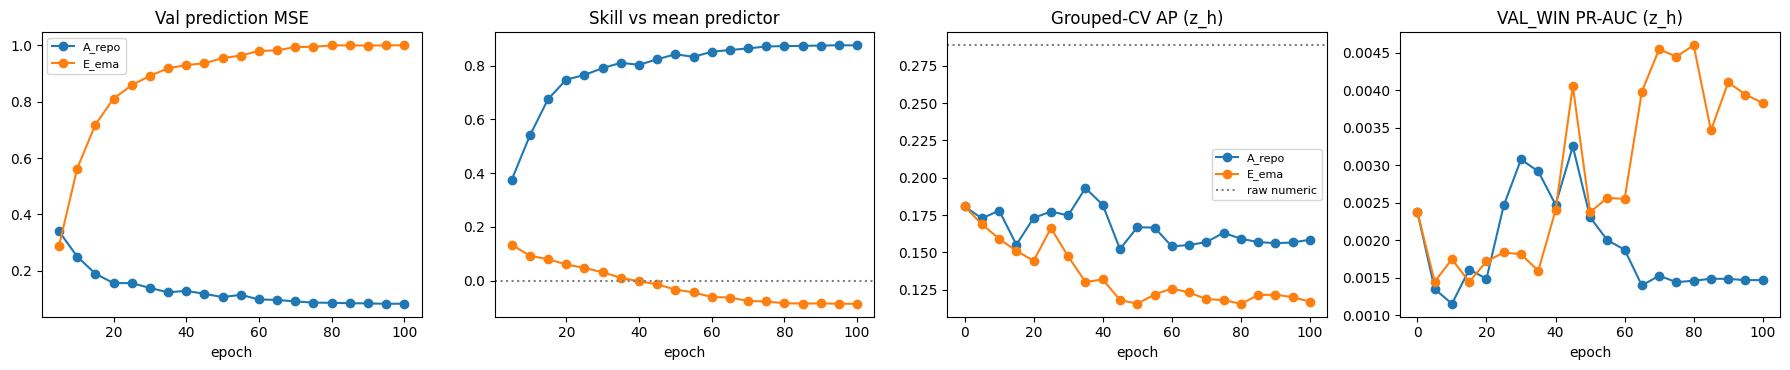

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt

EPOCHS     = getattr(FJ, "epochs", 100)
EVAL_EVERY = getattr(FJ, "eval_every", 10)
EMA_START  = getattr(FJ, "ema_start", 0.996)
EMA_END    = getattr(FJ, "ema_end", 1.0)
PROBE_MODES = ("z", "h", "z_h", "z_h_sur")
PROBE_C     = {"z": 0.1, "h": 0.1, "z_h": 0.1, "z_h_sur": 0.1}

idx_fit  = np.flatnonzero(HEAD_FIT_V)
idx_val  = np.flatnonzero(VAL_WIN)
idx_all  = np.concatenate([idx_fit, idx_val])
nf       = len(idx_fit)
y_fit    = Y_OBS_V[idx_fit]
y_val    = Y_TRUE[idx_val]
tail_m   = VAL_TAIL[idx_val]
groups_f = df["customer_id"].values[idx_fit]

print(f"validation: {len(idx_val):,} rows, {int(y_val.sum())} true frauds ({int(y_val[tail_m].sum())} in 7-23 Apr tail) "
      f"| probe trains on {nf:,} rows with {int(y_fit.sum())} labelled positives")

def make_reps(E):
    """Build candidate Fin-JEPA representations from fin_embed output."""
    z, h = E["z"], E["h"]
    sur  = E["sur"][:, None]
    has  = E["has"][:, None]
    return {
        "z":       z,
        "h":       h,
        "z_h":     np.hstack([z, h]),
        "z_h_sur": np.hstack([z, h, sur, has]),
    }

def cv_ap(Z, C_reg=0.1, y=y_fit, groups=groups_f):
    oof = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(Z, y, groups):
        mu, sd = Z[tr].mean(0), Z[tr].std(0) + 1e-6
        lr = LogisticRegression(C=C_reg, class_weight="balanced", max_iter=300).fit(np.clip((Z[tr] - mu) / sd, -8, 8), y[tr])
        oof[te] = lr.decision_function(np.clip((Z[te] - mu) / sd, -8, 8))
    return float(average_precision_score(y, oof))

def eval_checkpoint(model, target):
    E_all = fin_embed(model, idx_all, target=target)
    reps  = make_reps(E_all)
    # Label-free diagnostics on VAL_WIN portion
    E_val = {k: v[nf:] for k, v in E_all.items()}
    diag  = fin_diag(E_val)
    hz    = emb_health(reps["z"][nf:])
    hh    = emb_health(reps["h"][nf:])

    out = dict(
        val_loss=diag["loss"],
        skill_mean=diag["skill_vs_mean"],
        skill_persist=diag["skill_vs_persist"],
        eff_rank_z=hz["eff_rank"],
        std_z=hz["mean_dim_std"],
        eff_rank_h=hh["eff_rank"],
        std_h=hh["mean_dim_std"],
    )
    for mode in PROBE_MODES:
        Z = reps[mode]
        Zf, Zv = Z[:nf], Z[nf:]
        mu, sd = Zf.mean(0), Zf.std(0) + 1e-6
        Zfs = np.clip((Zf - mu) / sd, -8, 8).astype(np.float32)
        Zvs = np.clip((Zv - mu) / sd, -8, 8).astype(np.float32)
        lr = LogisticRegression(C=PROBE_C[mode], class_weight="balanced", max_iter=300).fit(Zfs, y_fit)
        sv = lr.decision_function(Zvs)
        out[f"cv_{mode}"]      = cv_ap(Zf, C_reg=PROBE_C[mode])
        out[f"val_pr_{mode}"]  = float(average_precision_score(y_val, sv))
        out[f"val_roc_{mode}"] = float(roc_auc_score(y_val, sv))
        out[f"tail_pr_{mode}"] = float(average_precision_score(y_val[tail_m], sv[tail_m])) if y_val[tail_m].sum() > 0 else np.nan
    return out

def pretrain_variant(name, cfg):
    ema = cfg["ema"]
    set_seed(SEED)
    model  = new_model(SEED)
    target = make_target(model) if ema else None

    opt   = torch.optim.AdamW(model.parameters(), lr=FJ.lr, weight_decay=FJ.wd)
    steps_per_ep = int(np.ceil(len(TRAIN_W) / FJ.batch_size))
    total_steps  = steps_per_ep * EPOCHS
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps, eta_min=1e-5)
    mom_iter = (EMA_START + i * (EMA_END - EMA_START) / max(1, total_steps) for i in range(total_steps + 5))

    rng = np.random.RandomState(SEED)
    logs, ckpts = [], {}

    def snap(ep, tr_loss, tr_pred, tr_sig):
        ev = eval_checkpoint(model, target)
        row = dict(variant=name, epoch=ep, train_loss=tr_loss, train_pred=tr_pred, train_sig=tr_sig, **ev)
        logs.append(row)
        ckpts[ep] = {
            "model":  {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            "target": {k: v.detach().cpu().clone() for k, v in target.state_dict().items()} if target is not None else None,
        }
        print(f"  [{name}] ep {ep:3d} | tr {tr_loss:.4f} | val_mse {ev['val_loss']:.4f} | "
              f"skill(mean={ev['skill_mean']:.3f}, pers={ev['skill_persist']:.3f}) | "
              f"cv_z_h {ev['cv_z_h']:.4f} | val_pr_z_h {ev['val_pr_z_h']:.4f} | eff_rank_z {ev['eff_rank_z']:.1f}")

    print(f"\n=== Pretraining {name} (ema={ema}) for {EPOCHS} epochs on {len(TRAIN_W):,} windows ===")
    t0 = time.time()
    snap(0, float("nan"), float("nan"), float("nan"))

    for ep in range(1, EPOCHS + 1):
        model.train()
        if target is not None: target.eval()
        perm = rng.permutation(len(TRAIN_W))
        tot_l, tot_p, tot_s = 0.0, 0.0, 0.0
        for i in range(0, len(TRAIN_W), FJ.batch_size):
            Wb = torch.from_numpy(TRAIN_W[perm[i:i + FJ.batch_size]]).to(DEVICE)
            loss, pl, sg = fin_loss(model, target, Wb, ema)
            assert torch.isfinite(loss), f"NaN/inf loss at {name} ep {ep}"
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), FJ.grad_clip)
            opt.step()
            if target is not None:
                m = next(mom_iter)
                with torch.no_grad():
                    for pq, pk in zip(model.parameters(), target.parameters()):
                        pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)
            sched.step()
            tot_l += loss.item(); tot_p += pl.item(); tot_s += sg.item()
        if ep % EVAL_EVERY == 0 or ep == EPOCHS:
            snap(ep, tot_l / steps_per_ep, tot_p / steps_per_ep, tot_s / steps_per_ep)

    print(f"  [{name}] finished in {(time.time() - t0)/60:.2f} min")
    return dict(log=pd.DataFrame(logs), ckpts=ckpts)

FIN_RUNS = {name: pretrain_variant(name, cfg) for name, cfg in VARIANTS.items()}

# ---- Selection & Summary (Point 11: same validation criterion as T-JEPA) ----
REF_CV = cv_ap(X_FIN[idx_fit, :N_NUM])
pd.set_option("display.width", 260, "display.max_columns", 25)
print(f"\nREFERENCE: raw numeric input features ({N_NUM} cols) -> grouped-CV AP = {REF_CV:.4f} (chance = {y_fit.mean():.4f})")

summ_rows = []
for name, run in FIN_RUNS.items():
    L = run["log"]
    z0 = L[L.epoch == 0].iloc[0]
    Lt = L[L.epoch > 0]
    best_cv  = Lt.sort_values(["cv_z_h", "skill_mean"], ascending=False).iloc[0]
    best_mse = Lt.sort_values("val_loss", ascending=True).iloc[0]
    summ_rows.append(dict(
        variant=name,
        selected_ep=int(best_cv.epoch),
        cv_untrained=z0.cv_z_h,
        cv_z=best_cv.cv_z,
        cv_h=best_cv.cv_h,
        cv_z_h=best_cv.cv_z_h,
        cv_z_h_sur=best_cv.cv_z_h_sur,
        val_pr_z_h=best_cv.val_pr_z_h,
        val_roc_z_h=best_cv.val_roc_z_h,
        skill_mean=best_cv.skill_mean,
        skill_persist=best_cv.skill_persist,
        eff_rank_z=best_cv.eff_rank_z,
        ep_min_val_loss=int(best_mse.epoch),
    ))
FIN_SUMM = pd.DataFrame(summ_rows)
print("\nSelected epoch per variant (best grouped-CV AP on z_h, ties -> higher skill_mean):")
print(FIN_SUMM.round(4).to_string(index=False))

# Save selected validation checkpoints
for r in FIN_SUMM.itertuples():
    torch.save(FIN_RUNS[r.variant]["ckpts"][r.selected_ep],
               os.path.join(WORK, f"finjepa_{r.variant}_val_ep{r.selected_ep}.pt"))

# ---- Plot progression ----
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for name, run in FIN_RUNS.items():
    L = run["log"]
    Lt = L[L.epoch > 0]
    ax[0].plot(Lt.epoch, Lt.val_loss, marker="o", label=name)
    ax[1].plot(Lt.epoch, Lt.skill_mean, marker="o", label=name)
    ax[2].plot(L.epoch, L.cv_z_h, marker="o", label=name)
    ax[3].plot(L.epoch, L.val_pr_z_h, marker="o", label=name)
ax[0].set_title("Val prediction MSE"); ax[0].legend(fontsize=8)
ax[1].axhline(0, color="grey", ls=":"); ax[1].set_title("Skill vs mean predictor")
ax[2].axhline(REF_CV, color="grey", ls=":", label="raw numeric"); ax[2].set_title("Grouped-CV AP (z_h)"); ax[2].legend(fontsize=8)
ax[3].set_title("VAL_WIN PR-AUC (z_h)")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Step 7 — Final Refit, Multi-Seed Test Evaluation & Baselines

Refits on all training rows across seeds `[42, 1042, 2042]` and evaluates `Fin-JEPA` variants against `LogReg`, `XGBoost`, and untrained encoder controls.

In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
import xgboost as xgb

SEEDS      = [42, 1042, 2042]
MODES      = ("z_h", "z_h_sur", "z", "h")
LR_C       = {"z_h": 0.1, "z_h_sur": 0.1, "z": 0.1, "h": 0.1}
MLP_SEEDS  = 2
ALERTS     = (0.005, 0.01, 0.02)
SEL        = {r.variant: int(r.selected_ep) for r in FIN_SUMM.itertuples()}
print("epochs selected on validation in Step 6:", SEL, "| seeds:", SEEDS)

# ---- 1. Refit scalers & one-hot vocab on ALL train rows (Protocol Step D) ----
M_F       = build_matrix(IS_TRAIN)
X_FIN_F   = M_F["X"]
N_NUM_F   = len(M_F["cols"])
XT        = torch.from_numpy(X_FIN_F).to(DEVICE)          # fin_loss & fin_embed read global XT
TRAIN_W_F = make_train_windows(IS_TRAIN, FJ.window, FJ.stride)
assert np.isfinite(X_FIN_F).all()
print(f"refit: scalers/vocab fitted on {IS_TRAIN.sum():,} train rows | X_FIN {X_FIN_F.shape} | train windows {TRAIN_W_F.shape}")

# ---- 2. Evaluation (hidden ground truth, TEST period only) ----
def flag_topk(score, frac):
    k = max(1, int(round(len(score) * frac))); fl = np.zeros(len(score), bool)
    fl[np.argsort(-score, kind="stable")[:k]] = True; return fl

def evaluate(score_all):
    s, y, ty = score_all[IS_TEST], Y_TRUE[IS_TEST], TYP[IS_TEST]
    m = {"pr_auc": average_precision_score(y, s), "roc_auc": roc_auc_score(y, s)}
    for a in ALERTS:
        fl = flag_topk(s, a)
        m[f"rec@{a:.1%}"]  = (fl & (y == 1)).sum() / y.sum()
        m[f"prec@{a:.1%}"] = (fl & (y == 1)).sum() / fl.sum()
    fl = flag_topk(s, 0.01)
    for t in ("ato", "emerge", "normal"):
        mm = (ty == t) & (y == 1)
        m[f"rec1%_{t}"] = float(fl[mm].mean()) if mm.any() else np.nan
    return m

RES, SC = [], {}
def record(model_name, mode, head, seed, score_all):
    RES.append(dict(model=model_name, mode=mode, head=head, seed=seed, **evaluate(score_all)))
    SC[f"{model_name}|{mode}|{head}|{seed}"] = np.asarray(score_all[IS_TEST], np.float32)

# ---- 3. Downstream heads (class-weighted; trained ONLY on mature train rows POOL / FIT / VAL with Y_OBS) ----
def fit_mlp(Zs, seed):
    set_seed(seed)
    net = nn.Sequential(
        nn.Linear(Zs.shape[1], 128), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(64, 1)
    ).to(DEVICE)
    Xf = torch.from_numpy(Zs[FIT]).to(DEVICE); yf = torch.from_numpy(Y_OBS[FIT]).float().to(DEVICE)
    Xv = torch.from_numpy(Zs[VAL]).to(DEVICE); yv = Y_OBS[VAL]
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    best, bad, state = -1.0, 0, None
    for ep in range(80):
        net.train(); perm = torch.randperm(len(Xf), device=DEVICE)
        for i in range(0, len(perm), 512):
            b = perm[i:i + 512]; opt.zero_grad(); lossf(net(Xf[b]).squeeze(1), yf[b]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): sv = net(Xv).squeeze(1).cpu().numpy()
        ap = average_precision_score(yv, sv) if yv.sum() > 0 else 0.0
        if ap > best:
            best, bad, state = ap, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= 15: break
    net.load_state_dict(state); net.eval()
    with torch.no_grad(): return net(torch.from_numpy(Zs).to(DEVICE)).squeeze(1).cpu().numpy()

def run_heads(Z, model_name, mode, seed):
    Z = np.asarray(Z, np.float32)
    mu, sd = Z[POOL].mean(0), Z[POOL].std(0) + 1e-6
    Zs = np.clip((Z - mu) / sd, -8, 8).astype(np.float32)
    lr = LogisticRegression(C=LR_C.get(mode, 0.1), class_weight="balanced", max_iter=300).fit(Zs[POOL], Y_OBS[POOL])
    record(model_name, mode, "LinearProbe", seed, lr.decision_function(Zs))
    record(model_name, mode, "MLP", seed, np.mean([fit_mlp(Zs, seed + k) for k in range(MLP_SEEDS)], axis=0))

# ---- 4. Pretrain Fin-JEPA on ALL train rows to the selected epoch (using the same 100-epoch LR/EMA schedule) ----
def pretrain_final(name, seed, stop_epoch):
    ema = VARIANTS[name]["ema"]
    set_seed(seed)
    model  = new_model(seed)
    target = make_target(model) if ema else None
    s0     = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    opt = torch.optim.AdamW(model.parameters(), lr=FJ.lr, weight_decay=FJ.wd)
    steps_per_ep = int(np.ceil(len(TRAIN_W_F) / FJ.batch_size))
    total_steps  = steps_per_ep * EPOCHS
    sched    = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps, eta_min=1e-5)
    mom_iter = (EMA_START + i * (EMA_END - EMA_START) / max(1, total_steps) for i in range(total_steps + 5))

    rng = np.random.RandomState(seed)
    for ep in range(1, stop_epoch + 1):
        model.train()
        if target is not None: target.eval()
        perm = rng.permutation(len(TRAIN_W_F))
        tot_l = 0.0
        for i in range(0, len(TRAIN_W_F), FJ.batch_size):
            Wb = torch.from_numpy(TRAIN_W_F[perm[i:i + FJ.batch_size]]).to(DEVICE)
            loss, _, _ = fin_loss(model, target, Wb, ema)
            assert torch.isfinite(loss), f"NaN/inf loss at {name} ep {ep}"
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), FJ.grad_clip)
            opt.step()
            if target is not None:
                m = next(mom_iter)
                with torch.no_grad():
                    for pq, pk in zip(model.parameters(), target.parameters()):
                        pk.data.mul_(m).add_((1.0 - m) * pq.detach().data)
            sched.step(); tot_l += loss.item()
        if ep % 5 == 0 or ep == stop_epoch:
            print(f"      [{name} seed {seed}] epoch {ep:2d}/{stop_epoch} loss {tot_l / steps_per_ep:.4f}")

    s1 = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    t1 = {k: v.detach().cpu().clone() for k, v in target.state_dict().items()} if target is not None else None
    del model, target, opt
    return s0, s1, t1

def embed_and_score(state_m, state_t, model_name, seed):
    m = new_model(seed); m.load_state_dict(state_m); m.to(DEVICE).eval()
    t = None
    if state_t is not None:
        t = make_target(m); t.load_state_dict(state_t); t.to(DEVICE).eval()
    E_all = fin_embed(m, np.arange(N), target=t)
    reps  = make_reps(E_all)
    for mode in MODES:
        run_heads(reps[mode], model_name, mode, seed)
    del m, t

# ---- 5. Run all seeds ----
t0 = time.time()
for seed in SEEDS:
    print(f"\n===== seed {seed} =====")
    Xnum = X_FIN_F[:, :N_NUM_F]
    mu, sd = Xnum[POOL].mean(0), Xnum[POOL].std(0) + 1e-6
    lr = LogisticRegression(C=0.1, class_weight="balanced", max_iter=500).fit(np.clip((Xnum[POOL] - mu) / sd, -8, 8), Y_OBS[POOL])
    record("raw features", "numeric", "LogReg", seed, lr.decision_function(np.clip((Xnum - mu) / sd, -8, 8)))

    spw = float(min((Y_OBS[FIT] == 0).sum() / max(Y_OBS[FIT].sum(), 1), 30.0))
    clf = xgb.XGBClassifier(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                            min_child_weight=2, reg_lambda=5.0, scale_pos_weight=spw, eval_metric="aucpr",
                            early_stopping_rounds=40, tree_method="hist", n_jobs=-1, random_state=seed, verbosity=0)
    clf.fit(X_FIN_F[FIT], Y_OBS[FIT], eval_set=[(X_FIN_F[VAL], Y_OBS[VAL])], verbose=False)
    record("raw features", "all", "XGBoost", seed, clf.predict(X_FIN_F, output_margin=True))

    untrained_done = False
    for name in VARIANTS:
        s0, s1, t1 = pretrain_final(name, seed, SEL[name])
        if not untrained_done:
            embed_and_score(s0, None, "Fin-JEPA untrained encoder", seed)
            untrained_done = True
        embed_and_score(s1, t1, f"Fin-JEPA [{name} @ ep {SEL[name]}]", seed)
    print(f"   elapsed {(time.time() - t0) / 60:.1f} min")

# ---- 6. Results Summary & Save ----
R = pd.DataFrame(RES)
METR = [("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC"), ("rec@1.0%", "Recall@1%"), ("prec@1.0%", "Prec@1%"),
        ("rec@0.5%", "Recall@0.5%"), ("rec@2.0%", "Recall@2%"), ("rec1%_emerge", "Rec emerge"), ("rec1%_ato", "Rec ato")]
g = R.groupby(["model", "mode", "head"])
summ = pd.DataFrame({n: g[c].apply(lambda x: f"{np.nanmean(x):.3f} ± {np.nanstd(x):.3f}") for c, n in METR})
summ["_s"] = g["pr_auc"].mean()
summ = summ.sort_values("_s", ascending=False).drop(columns="_s")

nT = int(Y_TRUE[IS_TEST].sum())
print(f"\nTEST: {IS_TEST.sum():,} charges, {nT} frauds ({int(((TYP=='emerge')&(Y_TRUE==1)&IS_TEST).sum())} emerge, "
      f"{int(((TYP=='ato')&(Y_TRUE==1)&IS_TEST).sum())} ato, {int(((TYP=='normal')&(Y_TRUE==1)&IS_TEST).sum())} normal) "
      f"| chance PR-AUC = {Y_TRUE[IS_TEST].mean():.4f} | mean ± std over {len(SEEDS)} seeds")
pd.set_option("display.width", 260, "display.max_colwidth", 65)
print(summ.to_string())

prim = R[(R["mode"] == "z_h") & (R["head"] == "LinearProbe")].groupby("model")[["pr_auc", "roc_auc", "rec@1.0%", "rec1%_emerge", "rec1%_ato"]].mean().round(3)
print("\nPRIMARY (pre-registered): LinearProbe on z_h [z, h], mean over seeds")
print(prim.to_string())

R.to_csv(os.path.join(WORK, "finjepa_final_results.csv"), index=False)
np.savez_compressed(os.path.join(WORK, "finjepa_test_scores.npz"),
                    ids=df.loc[IS_TEST, "id"].values.astype(str), y=Y_TRUE[IS_TEST], typ=TYP[IS_TEST],
                    **{k.replace("|", "__"): v for k, v in SC.items()})
print(f"\nsaved finjepa_final_results.csv and finjepa_test_scores.npz to {WORK}")

epochs selected on validation in Step 6: {'A_repo': 35, 'E_ema': 5} | seeds: [42, 1042, 2042]
refit: scalers/vocab fitted on 22,991 train rows | X_FIN (43716, 192) | train windows (3583, 32)

===== seed 42 =====
      [A_repo seed 42] epoch  5/35 loss 2.0263
      [A_repo seed 42] epoch 10/35 loss 1.4873
      [A_repo seed 42] epoch 15/35 loss 1.2418
      [A_repo seed 42] epoch 20/35 loss 1.1480
      [A_repo seed 42] epoch 25/35 loss 1.0597
      [A_repo seed 42] epoch 30/35 loss 0.9737
      [A_repo seed 42] epoch 35/35 loss 0.8975
      [E_ema seed 42] epoch  5/5 loss 1.6536
   elapsed 1.5 min

===== seed 1042 =====
      [A_repo seed 1042] epoch  5/35 loss 2.1050
      [A_repo seed 1042] epoch 10/35 loss 1.4809
      [A_repo seed 1042] epoch 15/35 loss 1.2314
      [A_repo seed 1042] epoch 20/35 loss 1.1466
      [A_repo seed 1042] epoch 25/35 loss 1.0642
      [A_repo seed 1042] epoch 30/35 loss 0.9883
      [A_repo seed 1042] epoch 35/35 loss 0.9313
      [E_ema seed 1042] epoch

## Step 8 — Confusion Matrices, ROC/PR Curves & Bootstrap CIs

Computes alert-budget confusion matrices (`0.5%`, `1.0%`, `2.0%`), fraud-type recall, 95% bootstrap confidence intervals, and ROC/PR plots.

6 models | scores averaged over seeds (rank-normalised) | test: 20,725 charges, 127 frauds

CONFUSION MATRIX COUNTS + METRICS at each alert budget (flag the top-k% highest scores):
                                                                                            model budget  flagged  TP  FP  FN    TN  precision  recall    F1   FPR
                                                                  raw features | numeric | LogReg   0.5%      104  26  78 101 20520      0.250   0.205 0.225 0.004
                                                                  raw features | numeric | LogReg   1.0%      207  52 155  75 20443      0.251   0.409 0.311 0.008
                                                                  raw features | numeric | LogReg   2.0%      414  89 325  38 20273      0.215   0.701 0.329 0.016
                                                                     raw features | all | XGBoost   0.5%      104   3 101 124 20497      0.029   0.024 0.026 0.005
    

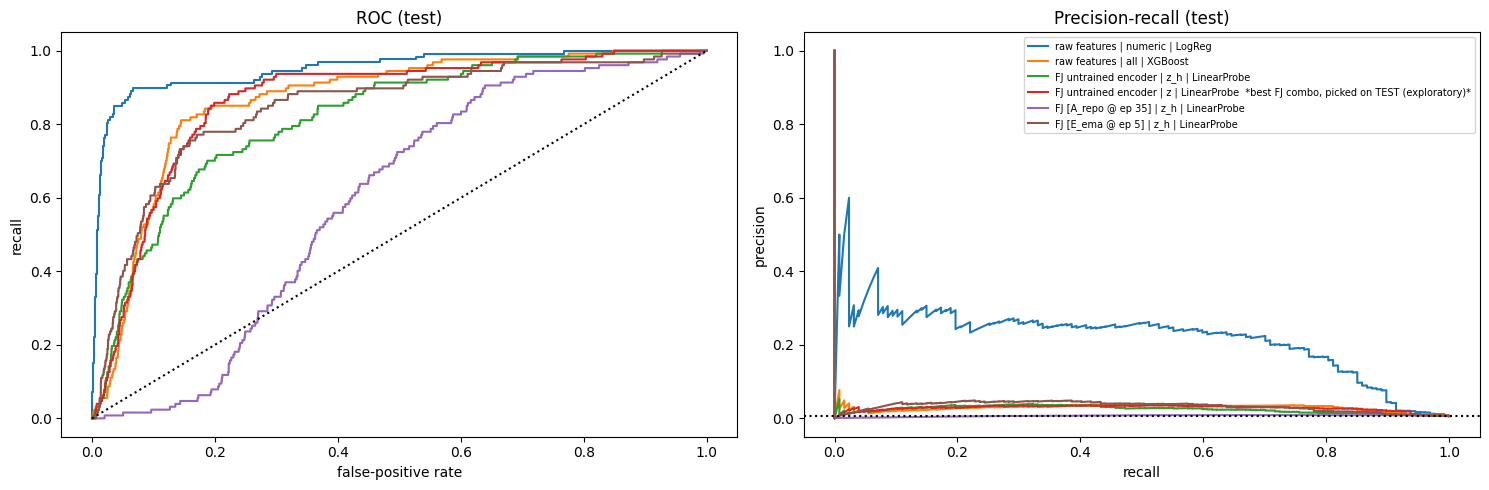

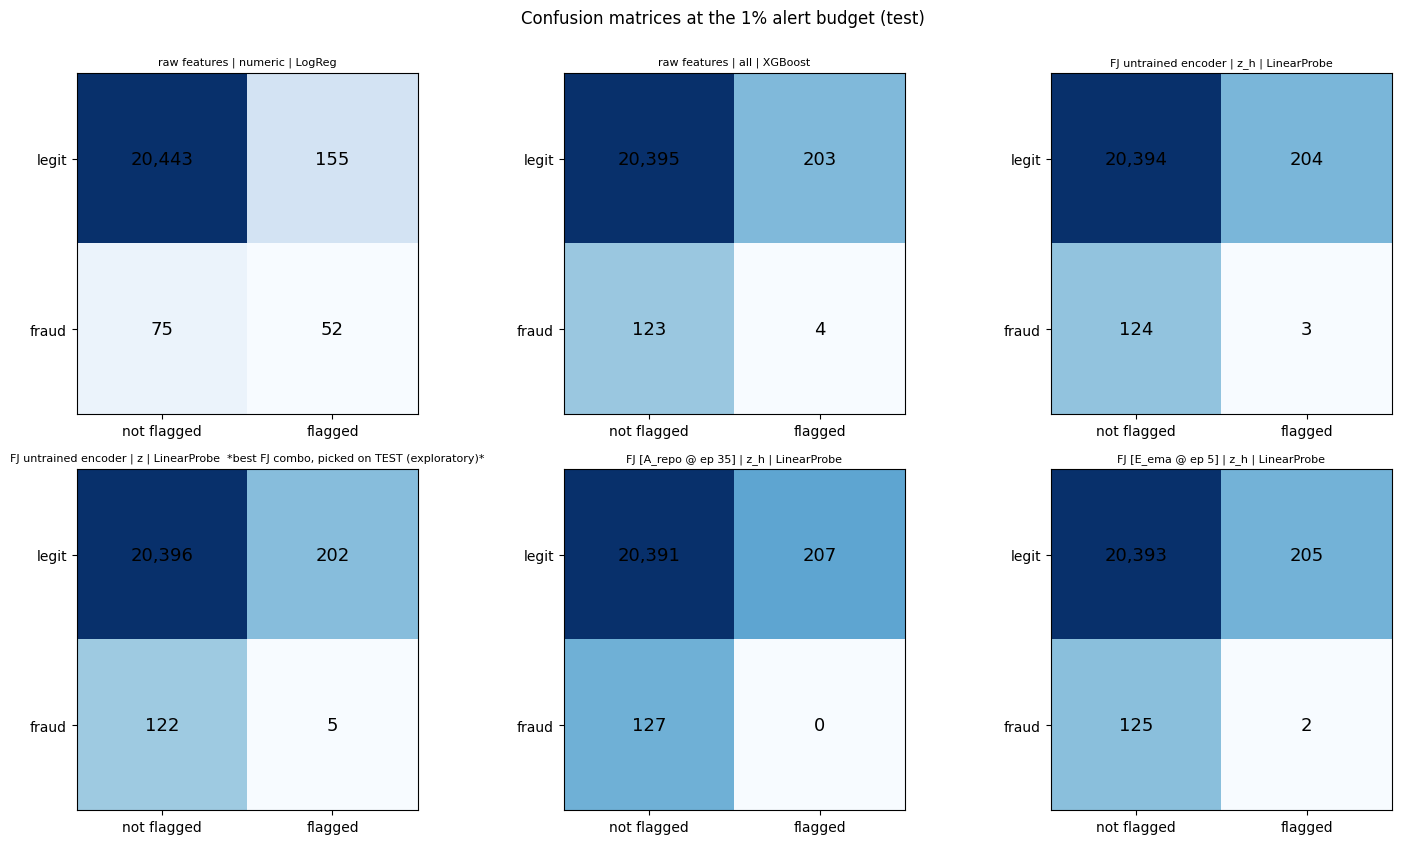

In [8]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from scipy.stats import rankdata
import matplotlib.pyplot as plt

BUDGETS = (0.005, 0.01, 0.02)
yT, tyT = Y_TRUE[IS_TEST], TYP[IS_TEST]
def _topk(s, frac):
    k = max(1, int(round(len(s) * frac))); fl = np.zeros(len(s), bool)
    fl[np.argsort(-s, kind="stable")[:k]] = True; return fl

# ---- 1. Select pre-registered primary + controls (+ best Fin-JEPA combo in hindsight, clearly labelled) ----
groups = {}
for k, v in SC.items():
    model, mode, head, seed = k.split("|")
    groups.setdefault((model, mode, head), []).append(v)

fj_means = R[R.model.str.startswith("Fin-JEPA")].groupby(["model", "mode", "head"]).pr_auc.mean()
best_fj  = fj_means.idxmax()

CHOSEN = {}
for (model, mode, head), arr in groups.items():
    primary = (mode == "z_h" and head == "LinearProbe" and model.startswith("Fin-JEPA"))
    control = (model == "raw features")
    if primary or control or (model, mode, head) == best_fj:
        tag = "  *best Fin-JEPA combo, picked on TEST (exploratory)*" if ((model, mode, head) == best_fj and not primary) else ""
        CHOSEN[f"{model} | {mode} | {head}{tag}"] = np.mean([rankdata(a) / len(a) for a in arr], axis=0)

print(f"{len(CHOSEN)} models | scores averaged over seeds (rank-normalised) | test: {len(yT):,} charges, {int(yT.sum())} frauds\n")

# ---- 2. Confusion matrix counts + metrics at each alert budget ----
rows = []
for name, s in CHOSEN.items():
    for b in BUDGETS:
        fl = _topk(s, b)
        tp = int((fl & (yT == 1)).sum()); fp = int((fl & (yT == 0)).sum())
        fn = int((~fl & (yT == 1)).sum()); tn = int((~fl & (yT == 0)).sum())
        p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
        rows.append(dict(model=name, budget=f"{b:.1%}", flagged=int(fl.sum()), TP=tp, FP=fp, FN=fn, TN=tn,
                         precision=p, recall=r, F1=2 * p * r / max(p + r, 1e-12), FPR=fp / max(fp + tn, 1)))
CM = pd.DataFrame(rows)
pd.set_option("display.width", 260, "display.max_colwidth", 75)
print("CONFUSION MATRIX COUNTS + METRICS at each alert budget (flag the top-k% highest scores):")
print(CM.round(3).to_string(index=False))

# ---- 3. Recall by fraud type at the 1% budget ----
print("\nRECALL BY FRAUD TYPE at the 1% budget (caught / total):")
tr = []
for name, s in CHOSEN.items():
    fl = _topk(s, 0.01); r = {"model": name}
    for t in ("emerge", "ato", "normal"):
        m = (tyT == t) & (yT == 1)
        r[t] = f"{int(fl[m].sum())}/{int(m.sum())}"
    tr.append(r)
print(pd.DataFrame(tr).to_string(index=False))

# ---- 4. PR-AUC / ROC-AUC with 95% bootstrap confidence intervals ----
rng = np.random.RandomState(0); B = 300; ci = []
idxs = [rng.randint(0, len(yT), len(yT)) for _ in range(B)]
for name, s in CHOSEN.items():
    ap = [average_precision_score(yT[i], s[i]) for i in idxs if yT[i].sum() > 0]
    ci.append(dict(model=name, PR_AUC=average_precision_score(yT, s),
                   PR_lo=np.percentile(ap, 2.5), PR_hi=np.percentile(ap, 97.5), ROC_AUC=roc_auc_score(yT, s)))
CI = pd.DataFrame(ci)
print(f"\nPR-AUC / ROC-AUC with 95% bootstrap interval (chance PR-AUC = {yT.mean():.4f}):")
print(CI.round(3).to_string(index=False))

# ---- 5. Direct comparison with T-JEPA (if tjepa_final_results.csv exists in WORK) ----
tj_csv = os.path.join(WORK, "tjepa_final_results.csv")
if os.path.exists(tj_csv):
    RTJ = pd.read_csv(tj_csv)
    tj_prim = RTJ[(RTJ["mode"] == "cls_mean") & (RTJ["head"] == "LinearProbe")].groupby("model")[["pr_auc", "roc_auc", "rec@1.0%", "rec1%_emerge", "rec1%_ato"]].mean()
    fj_prim = R[(R["mode"] == "z_h") & (R["head"] == "LinearProbe")].groupby("model")[["pr_auc", "roc_auc", "rec@1.0%", "rec1%_emerge", "rec1%_ato"]].mean()
    raw_ref = R[(R["model"] == "raw features") & (R["mode"] == "numeric")].groupby("model")[["pr_auc", "roc_auc", "rec@1.0%", "rec1%_emerge", "rec1%_ato"]].mean()
    comp = pd.concat([raw_ref, tj_prim, fj_prim]).round(3)
    print("\n=== HEAD-TO-HEAD COMPARISON: Raw Baseline vs T-JEPA (LinearProbe) vs Fin-JEPA (LinearProbe) ===")
    print(comp.to_string())

# ---- 6. ROC, Precision-Recall, and Confusion Matrix plots ----
short = {n: n.replace("Fin-JEPA ", "FJ ").replace("  *best Fin-JEPA combo, picked on TEST (exploratory)*", " [hindsight]") for n in CHOSEN}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, s in CHOSEN.items():
    fpr_, tpr_, _ = roc_curve(yT, s); ax[0].plot(fpr_, tpr_, label=short[n])
    p_, r_, _ = precision_recall_curve(yT, s); ax[1].plot(r_, p_, label=short[n])
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("recall"); ax[0].set_title("ROC (test)")
ax[1].axhline(yT.mean(), color="k", ls=":"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall (test)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

n = len(CHOSEN); cols = min(3, n); rws = int(np.ceil(n / cols))
fig, axs = plt.subplots(rws, cols, figsize=(5 * cols, 4.2 * rws)); axs = np.atleast_1d(axs).ravel()
for a, (name, s) in zip(axs, CHOSEN.items()):
    fl = _topk(s, 0.01)
    M = np.array([[(~fl & (yT == 0)).sum(), (fl & (yT == 0)).sum()],
                  [(~fl & (yT == 1)).sum(), (fl & (yT == 1)).sum()]])
    a.imshow(np.log10(M + 1), cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, f"{M[i, j]:,}", ha="center", va="center", fontsize=13, color="black")
    a.set_xticks([0, 1]); a.set_xticklabels(["not flagged", "flagged"])
    a.set_yticks([0, 1]); a.set_yticklabels(["legit", "fraud"])
    a.set_title(short[name], fontsize=8)
for a in axs[n:]: a.axis("off")
plt.suptitle("Confusion matrices at the 1% alert budget (test)", y=1.0); plt.tight_layout(); plt.show()